<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# Ciências da Computação [》](https://www.pucsp.br/graduacao/ciencia-da-computacao)

## Inteligência Artificial

IA ML (Machine Learning, Aprendizagem de Máquina)

**Objetivo desta aula e LAB explorar os modelos de Redes Neurais Artificiais (ANN - Artificial Neural Network) com Scikit-Learn em Python, sobre os dados da Lego**

Inteligência Artificial - ML com Scikit-learn

PARTE II - LAB

### Dados (LEGO)

LEGO sets released from 1970 to 2022, including details on each set's theme, pieces, recommended age, retail price, and image.

https://mavenanalytics.io/data-playground/lego-sets


## TODO

LAB:

EM DUPLAS (Pairing)<br>
Entrega amanhã (24 horas) em atividade no MS Teams
- Entregar o  .ipynb

- Baixar os dados
- Carregar em data frame Pandas
- Exibir visualmente os dados faltantes
- Organizar e limpar os dados
- Completar os kits de lego (Lego Sets) sem preço
   - Modelagem: Usando redes neurais artificial (ANN)
   - Scikit-learn
- Realizar análise e visualizações
   

Baixando dados do site, com o comando do Linux `wget` e o magic **!**

In [1]:
!wget https://maven-datasets.s3.amazonaws.com/LEGO+Sets/LEGO+Sets.zip

--2026-11-23 13:21:34--  https://maven-datasets.s3.amazonaws.com/LEGO+Sets/LEGO+Sets.zip
Resolving maven-datasets.s3.amazonaws.com (maven-datasets.s3.amazonaws.com)... 16.15.214.171, 16.15.255.18, 52.216.243.72, ...
Connecting to maven-datasets.s3.amazonaws.com (maven-datasets.s3.amazonaws.com)|16.15.214.171|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 536301 (524K) [application/zip]
Saving to: ‘LEGO+Sets.zip’

LEGO+Sets.zip       100%[===================>] 523.73K   593KB/s    in 0.9s    

2026-11-23 13:21:36 (593 KB/s) - ‘LEGO+Sets.zip’ saved [536301/536301]



Descompactando arquivo zip

In [2]:
!unzip *.zip

Archive:  LEGO+Sets.zip
  inflating: lego_sets.csv           
  inflating: lego_sets_data_dictionary.csv  


Listando os arquivos na pasta atual

In [3]:
!ls -l

total 4380
-rw-r--r-- 1 root root 3936470 Jan  3  2024 lego_sets.csv
-rw-r--r-- 1 root root     532 Jan  3  2024 lego_sets_data_dictionary.csv
-rw-r--r-- 1 root root  536301 Jan  3  2024 LEGO+Sets.zip
drwxr-xr-x 1 root root    4096 Nov 18 15:58 sample_data


Importando LIBs de EDA (Exploratory Data Analisys)


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno


Carregando e visualizando dados

In [5]:
lego_df = pd.read_csv('lego_sets.csv')

lego_df.head()

,set_id,name,year,theme,subtheme,themeGroup,category,pieces,minifigs,agerange_min,US_retailPrice,bricksetURL,thumbnailURL,imageURL
0,1-8,Small house set,1970,Minitalia,NaN,Vintage,Normal,67.0,NaN,NaN,NaN,https://brickset.com/sets/1-8,https://images.brickset.com/sets/small/1-8.jpg,https://images.brickset.com/sets/images/1-8.jpg
1,2-8,Medium house set,1970,Minitalia,NaN,Vintage,Normal,109.0,NaN,NaN,NaN,https://brickset.com/sets/2-8,https://images.brickset.com/sets/small/2-8.jpg,https://images.brickset.com/sets/images/2-8.jpg
2,3-6,Medium house set,1970,Minitalia,NaN,Vintage,Normal,158.0,NaN,NaN,NaN,https://brickset.com/sets/3-6,https://images.brickset.com/sets/small/3-6.jpg,https://images.brickset.com/sets/images/3-6.jpg
3,4-4,Large house set,1970,Minitalia,NaN,Vintage,Normal,233.0,NaN,NaN,NaN,https://brickset.com/sets/4-4,https://images.brickset.com/sets/small/4-4.jpg,https://images.brickset.com/sets/images/4-4.jpg
4,4-6,Mini House and Vehicles,1970,Samsonite,Model Maker,Vintage,Normal,NaN,NaN,NaN,NaN,https://brickset.com/sets/4-6,NaN,NaN


Buscando os valores faltantes (nulls)

In [6]:
# show missing values
lego_df.isnull().sum()

,0
set_id,0
name,0
year,0
theme,0
subtheme,3556
themeGroup,2
category,0
pieces,3924
minifigs,10058
agerange_min,11670


Visualizando valores faltantes (nulls)

<Axes: >

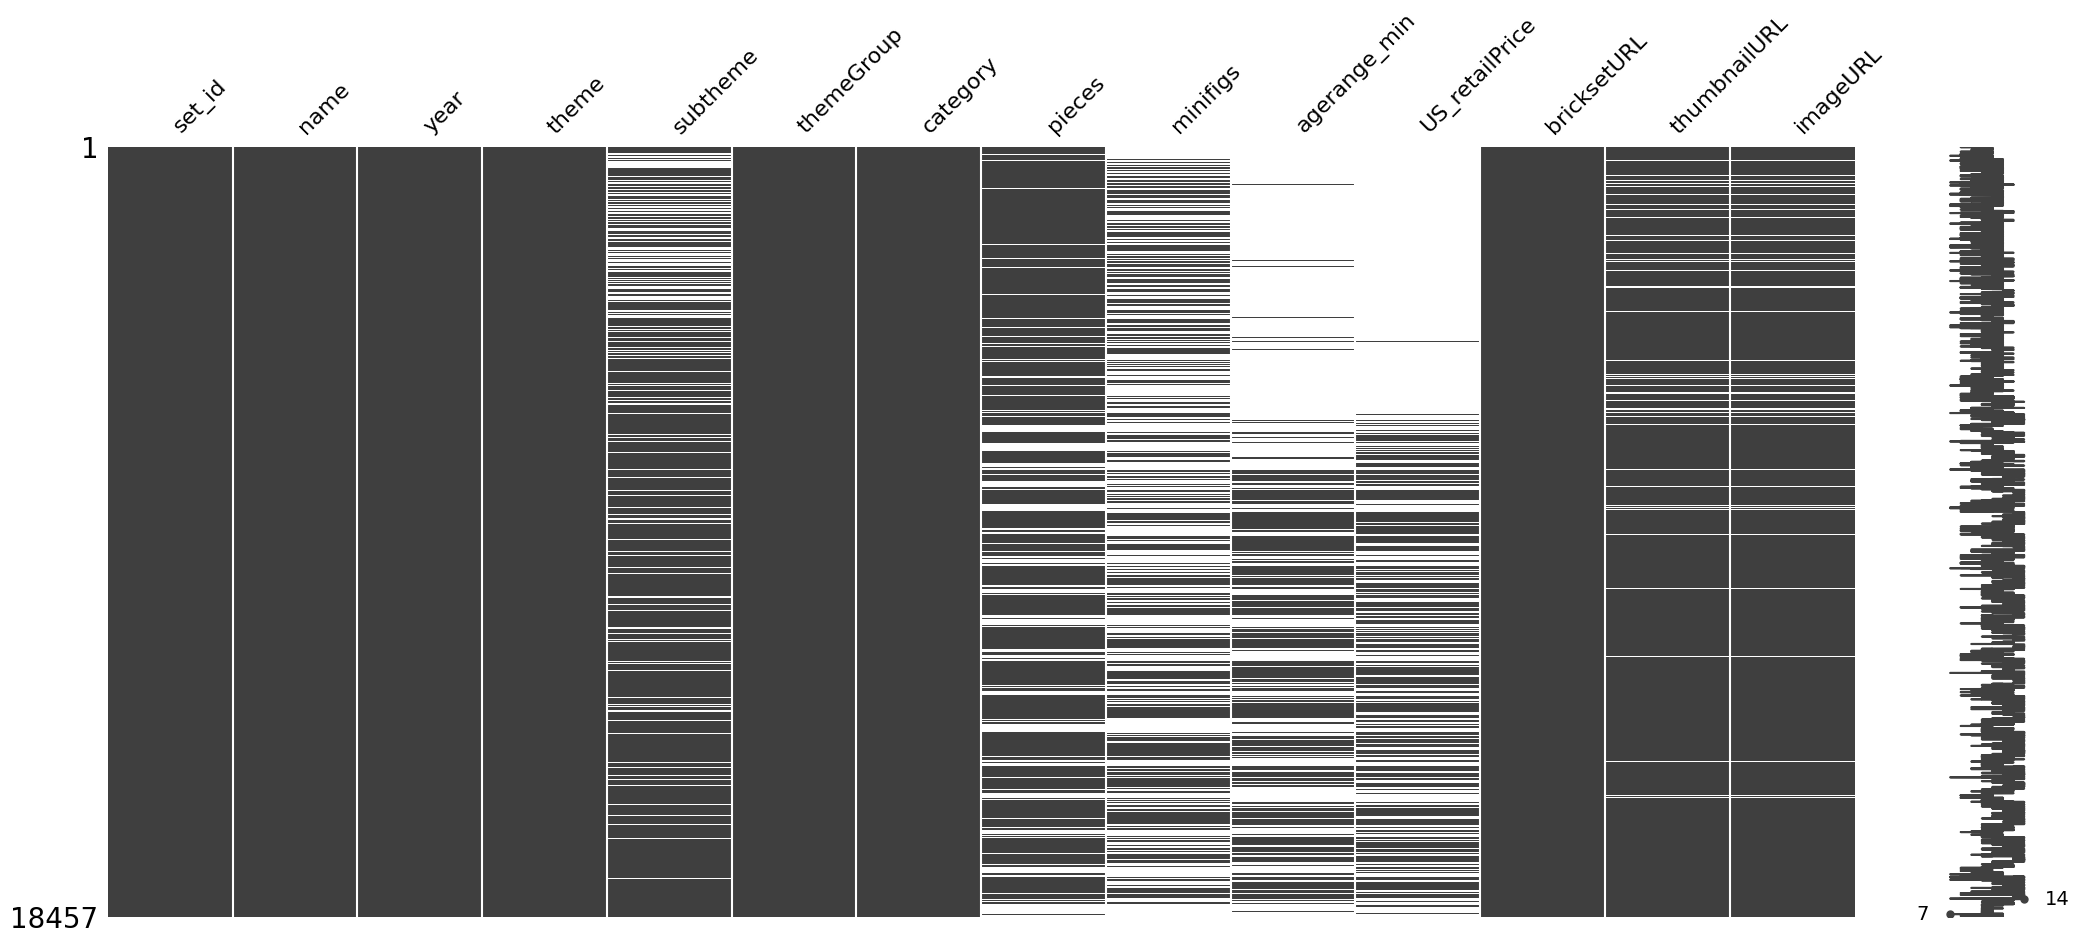

In [7]:
#Visualize missing values
msno.matrix(lego_df)


<Axes: >

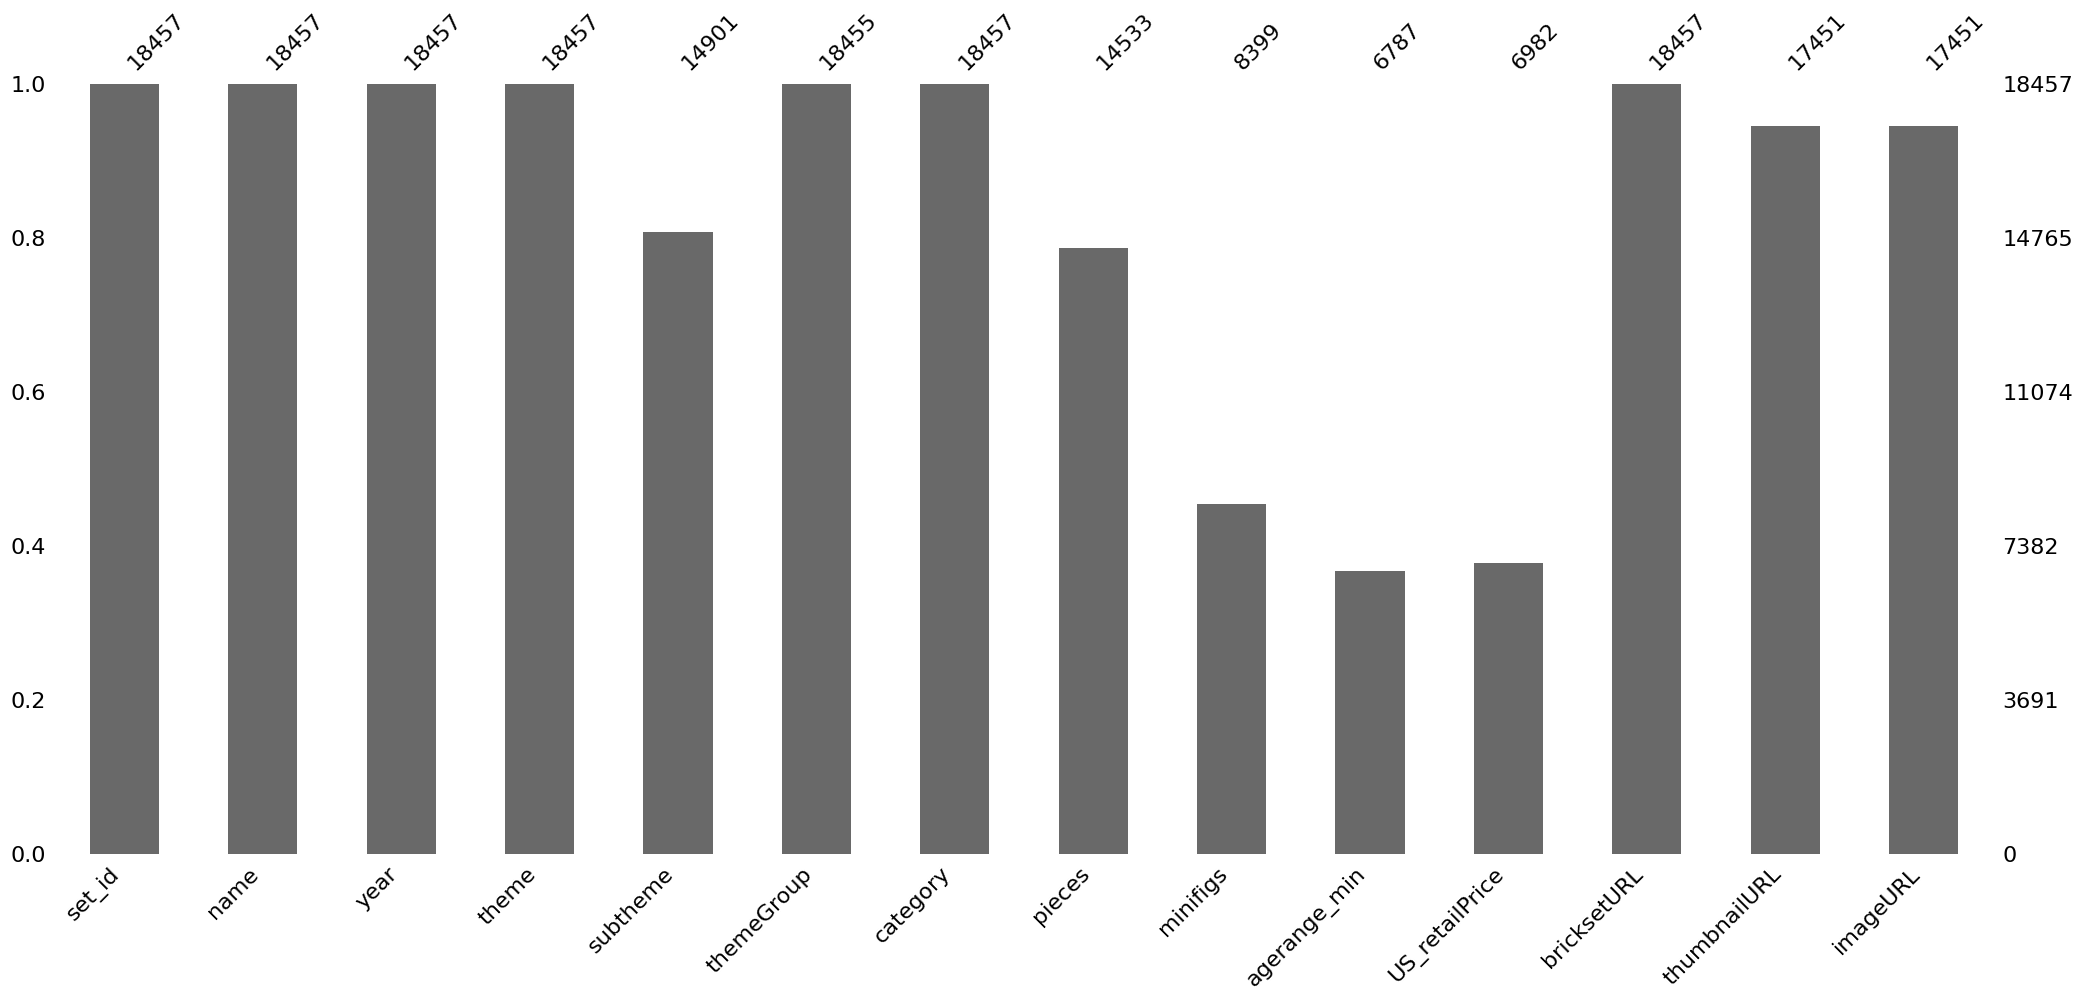

In [8]:
msno.bar(lego_df)


<Axes: >

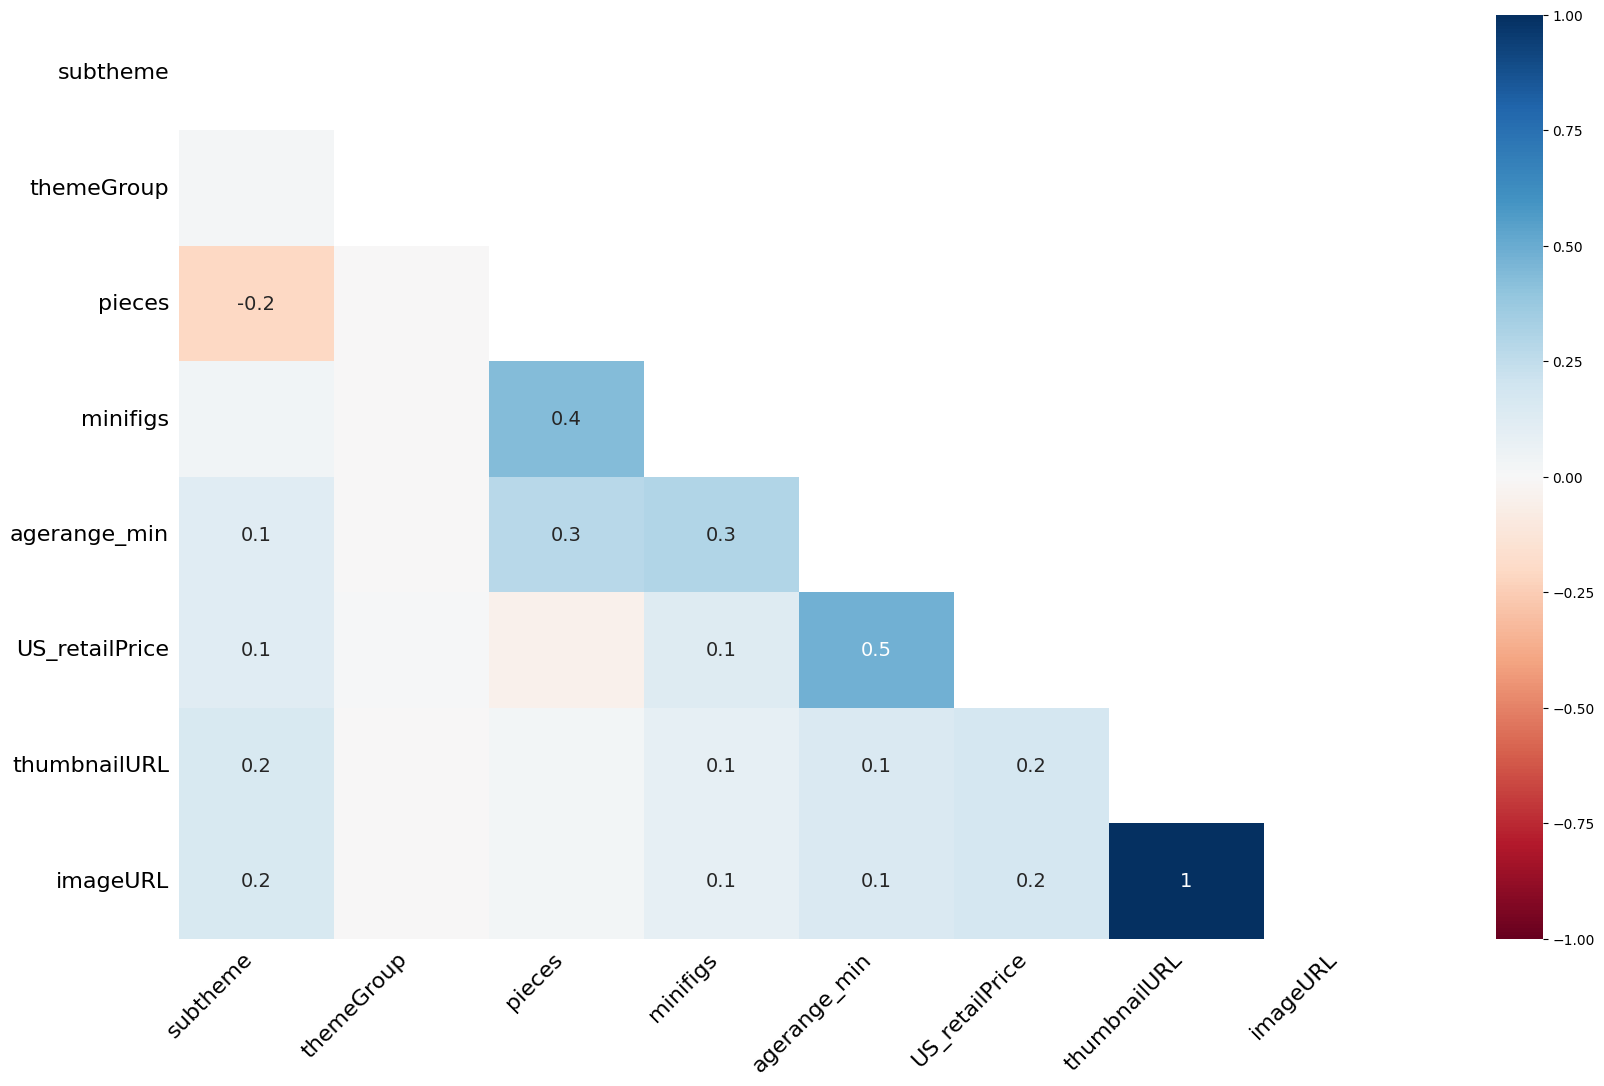

In [9]:
msno.heatmap(lego_df)


In [10]:
# Explorando e limpando dados

In [11]:
lego_df.nunique()

,0
set_id,18457
name,15374
year,53
theme,154
subtheme,895
themeGroup,16
category,7
pieces,1402
minifigs,33
agerange_min,15


Atividade: Criar uma coluna nova `price` e completar usando o modelo de redes neurais do Scikit-Learn (ANN), todos os conjuntos de leve devem

```
# Isto está formatado como código
```

ter preço.

> Adicionar aspas



Quais as colunas importantes para prever o preço??

In [12]:
# Organizar e limpar os dados

In [13]:
lego_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18457 entries, 0 to 18456
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   set_id          18457 non-null  object 
 1   name            18457 non-null  object 
 2   year            18457 non-null  int64  
 3   theme           18457 non-null  object 
 4   subtheme        14901 non-null  object 
 5   themeGroup      18455 non-null  object 
 6   category        18457 non-null  object 
 7   pieces          14533 non-null  float64
 8   minifigs        8399 non-null   float64
 9   agerange_min    6787 non-null   float64
 10  US_retailPrice  6982 non-null   float64
 11  bricksetURL     18457 non-null  object 
 12  thumbnailURL    17451 non-null  object 
 13  imageURL        17451 non-null  object 
dtypes: float64(4), int64(1), object(9)
memory usage: 2.0+ MB


In [14]:
lego_df.describe()

,year,pieces,minifigs,agerange_min,US_retailPrice
count,18457.000000,14533.000000,8399.000000,6787.000000,6982.000000
mean,2007.960611,226.473749,2.663650,6.637542,37.534817
std,11.948666,469.988785,2.897857,2.780091,54.382712
min,1970.000000,0.000000,1.000000,1.000000,1.490000
25%,2001.000000,23.000000,1.000000,5.000000,9.990000
50%,2011.000000,70.000000,2.000000,6.000000,19.990000
75%,2017.000000,242.000000,3.000000,8.000000,39.990000
max,2022.000000,11695.000000,80.000000,18.000000,849.990000


In [15]:
lego_df.isnull().sum()

,0
set_id,0
name,0
year,0
theme,0
subtheme,3556
themeGroup,2
category,0
pieces,3924
minifigs,10058
agerange_min,11670


In [16]:
lego_df['theme'].nunique()

154

In [17]:
lego_df['subtheme'].nunique()

895

In [18]:
lego_df['themeGroup'].nunique()

16

In [19]:
lego_df['category'].nunique()

7

In [20]:
(lego_df['subtheme'].value_counts() >50).value_counts()

,count
count,
False,841
True,54


In [21]:
subthemes_frequentes = lego_df['subtheme'].value_counts()
subthemes_frequentes = subthemes_frequentes[subthemes_frequentes > 0].index

df1 = lego_df[lego_df['subtheme'].isin(subthemes_frequentes)].copy()
df1['subtheme'].count()

np.int64(14901)

In [22]:
lego_df[~lego_df['subtheme'].isin(subthemes_frequentes)].count()

,0
set_id,3556
name,3556
year,3556
theme,3556
subtheme,0
themeGroup,3554
category,3556
pieces,3417
minifigs,1489
agerange_min,890


In [23]:
lego_df['category'].value_counts()

,count
category,
Normal,12757
Gear,2832
Other,1094
Book,631
Collection,578
Extended,501
Random,64


In [24]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

lego_df['category_int'] = le.fit_transform(lego_df['category'])

In [25]:
lego_df['themeGroup'].value_counts()

,count
themeGroup,
Miscellaneous,5891
Licensed,2509
Modern day,2357
Pre-school,1537
Action/Adventure,1397
Basic,863
Model making,719
Technical,588
Constraction,502


In [26]:
lego_df['theme_group_int'] = le.fit_transform(lego_df['themeGroup'])

In [27]:

lego_df['theme_group_int'].nunique()

17

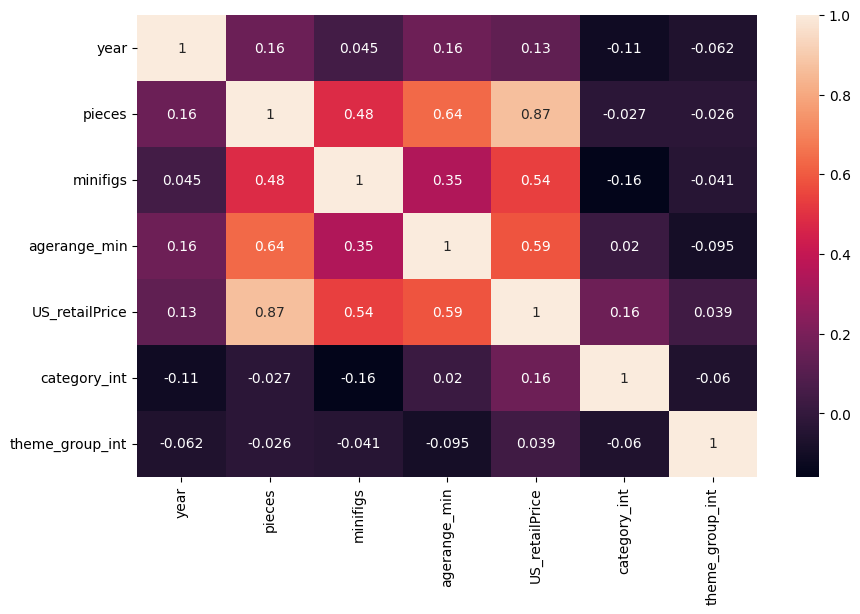

In [28]:
corr = lego_df.corr(numeric_only=True)

plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True)
plt.show()

In [29]:
!pip install sweetviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 34.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [sweetviz]


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import sweetviz as sv

In [31]:
report = sv.analyze(lego_df)

                                             |          | [  0%]   00:00 -> (? left)

In [32]:
report.show_html()


Report SWEETVIZ_REPORT.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


In [33]:
lego_df.groupby('year')['US_retailPrice'].mean()

,US_retailPrice
year,
1970,NaN
1971,NaN
1972,NaN
1973,NaN
1974,NaN
1975,NaN
1976,NaN
1977,NaN
1978,NaN


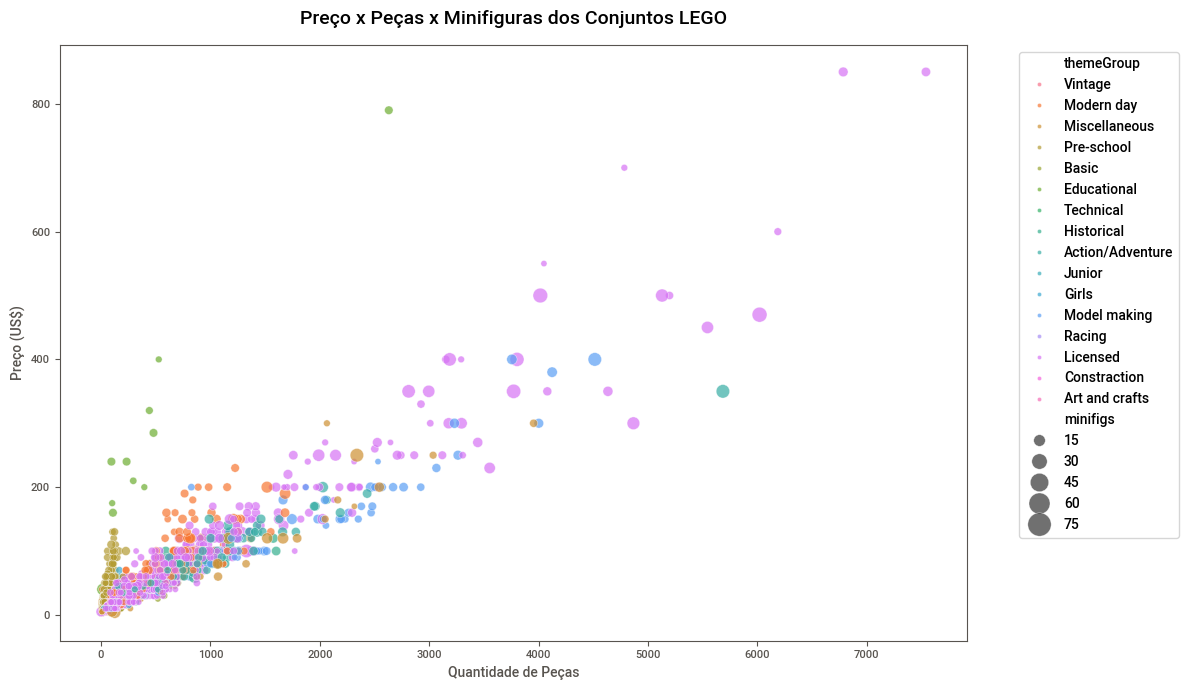

In [34]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=lego_df,
    x='pieces',
    y='US_retailPrice',
    hue='themeGroup',
    size='minifigs',
    sizes=(20, 300),
    alpha=0.7
)

plt.title(
    'Preço x Peças x Minifiguras dos Conjuntos LEGO',
    fontsize=14,
    pad=15
)

plt.xlabel('Quantidade de Peças')
plt.ylabel('Preço (US$)')

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

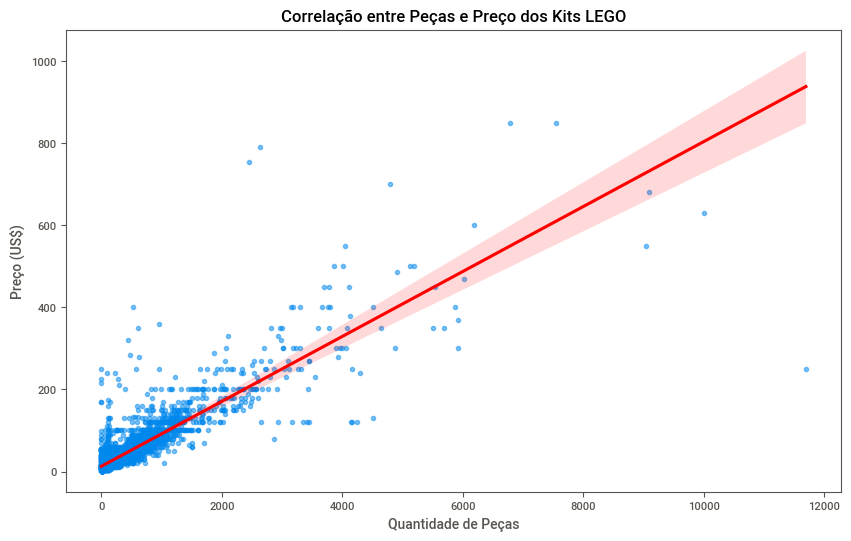

In [35]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=lego_df,
    x='pieces',
    y='US_retailPrice',
    scatter_kws={'alpha':0.5},
    line_kws={'color':'red'}
)

plt.title('Correlação entre Peças e Preço dos Kits LEGO')
plt.xlabel('Quantidade de Peças')
plt.ylabel('Preço (US$)')

plt.show()

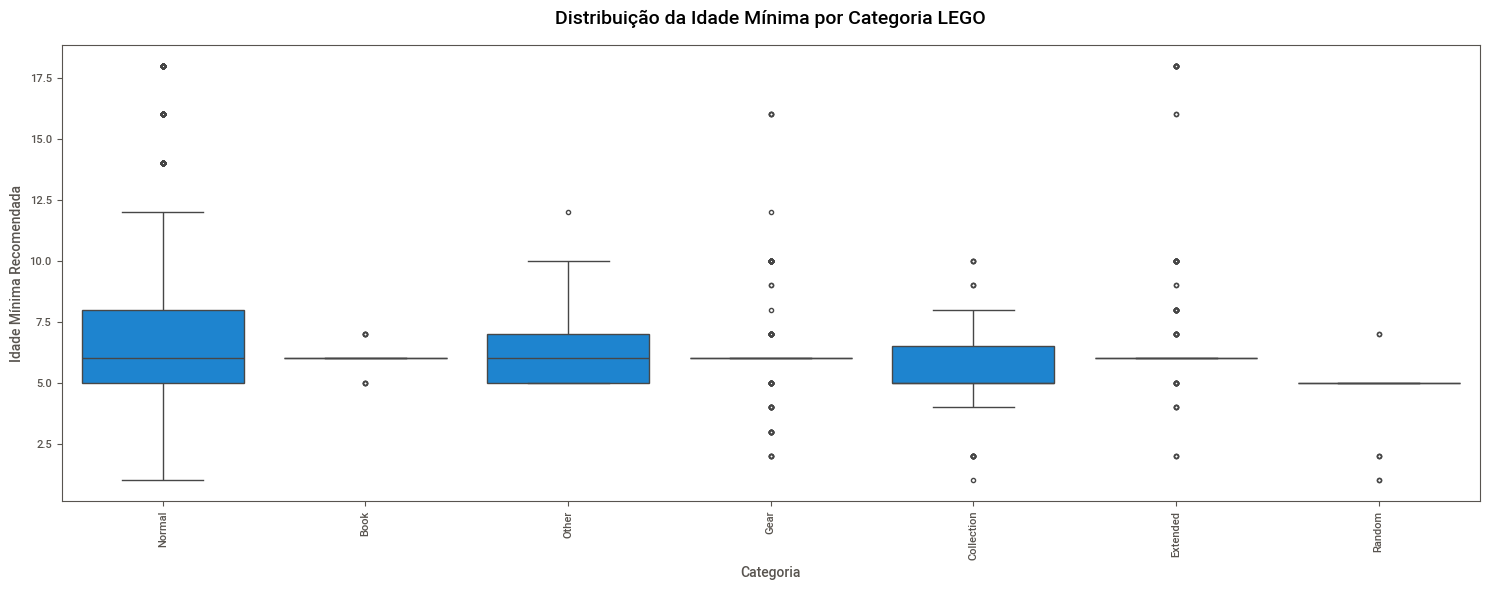

In [36]:
plt.figure(figsize=(15, 6))

sns.boxplot(
    data=lego_df,
    x='category',
    y='agerange_min'
)

plt.title(
    'Distribuição da Idade Mínima por Categoria LEGO',
    fontsize=14,
    pad=15
)

plt.xlabel('Categoria')
plt.ylabel('Idade Mínima Recomendada')

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [37]:
# Criando uma cópia para trabalhar de forma segura
df_model = lego_df[["year", "pieces", "minifigs", "US_retailPrice", "agerange_min", "category_int", "theme_group_int"]].copy()

In [38]:
df_model.describe()

,year,pieces,minifigs,US_retailPrice,agerange_min,category_int,theme_group_int
count,18457.000000,14533.000000,8399.000000,6982.000000,6787.000000,18457.000000,18457.000000
mean,2007.960611,226.473749,2.663650,37.534817,6.637542,3.627783,8.230807
std,11.948666,469.988785,2.897857,54.382712,2.780091,1.012676,3.650065
min,1970.000000,0.000000,1.000000,1.490000,1.000000,0.000000,0.000000
25%,2001.000000,23.000000,1.000000,9.990000,5.000000,4.000000,8.000000
50%,2011.000000,70.000000,2.000000,19.990000,6.000000,4.000000,9.000000
75%,2017.000000,242.000000,3.000000,39.990000,8.000000,4.000000,11.000000
max,2022.000000,11695.000000,80.000000,849.990000,18.000000,6.000000,16.000000


In [39]:
estatisticas = pd.DataFrame({
    'count': lego_df.select_dtypes(include='number').count(),
    'mean': lego_df.select_dtypes(include='number').mean(),
    'median': lego_df.select_dtypes(include='number').median(),
    'mode': lego_df.select_dtypes(include='number').mode().iloc[0],
    'std': lego_df.select_dtypes(include='number').std(),
    'min': lego_df.select_dtypes(include='number').min(),
    'q1': lego_df.select_dtypes(include='number').quantile(0.25),
    'q3': lego_df.select_dtypes(include='number').quantile(0.75),
    'max': lego_df.select_dtypes(include='number').max(),
})

estatisticas.round(2)

,count,mean,median,mode,std,min,q1,q3,max
year,18457,2007.96,2011.00,2022.00,11.95,1970.00,2001.00,2017.00,2022.00
pieces,14533,226.47,70.00,6.00,469.99,0.00,23.00,242.00,11695.00
minifigs,8399,2.66,2.00,1.00,2.90,1.00,1.00,3.00,80.00
agerange_min,6787,6.64,6.00,6.00,2.78,1.00,5.00,8.00,18.00
US_retailPrice,6982,37.53,19.99,19.99,54.38,1.49,9.99,39.99,849.99
category_int,18457,3.63,4.00,4.00,1.01,0.00,4.00,4.00,6.00
theme_group_int,18457,8.23,9.00,9.00,3.65,0.00,8.00,11.00,16.00


In [40]:
df_model['agerange_min'] = (
    df_model.groupby('category_int')['agerange_min']
           .transform(lambda x: x.fillna(x.median()))
)

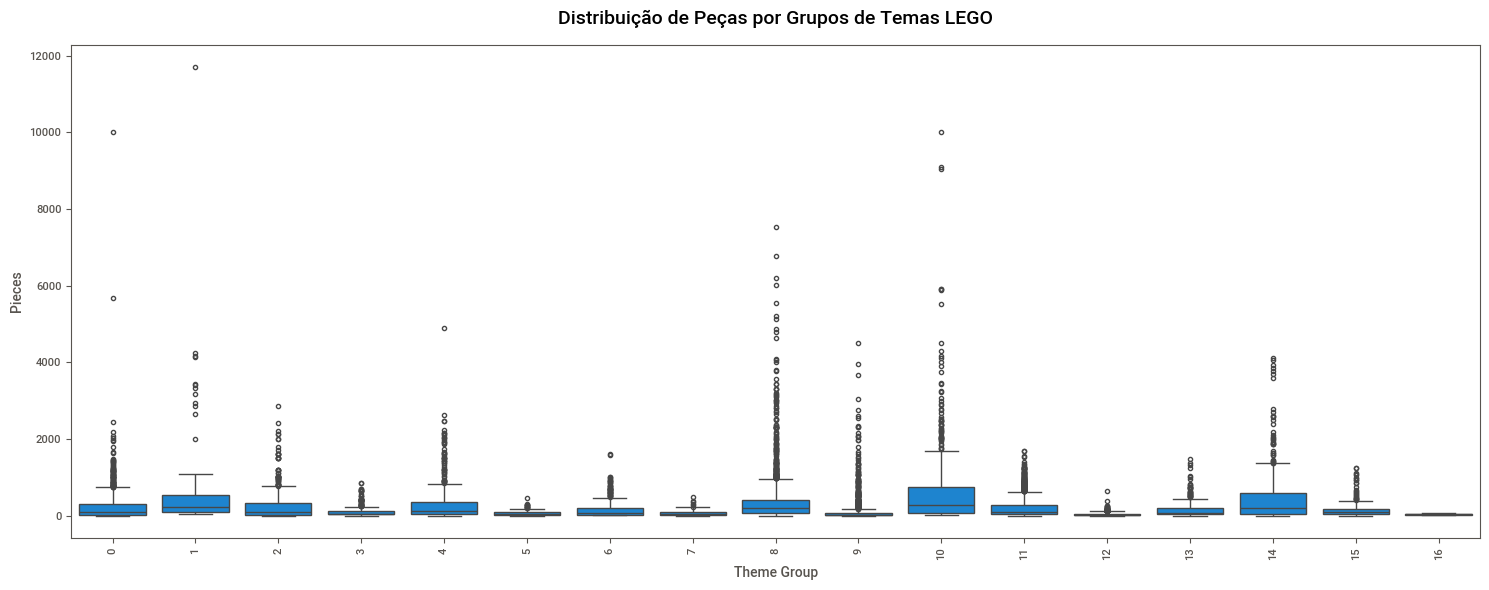

In [41]:
plt.figure(figsize=(15, 6))

sns.boxplot(
    data=df_model,
    x='theme_group_int',
    y='pieces'
)

plt.title(
    'Distribuição de Peças por Grupos de Temas LEGO',
    fontsize=14,
    pad=15
)

plt.xlabel('Theme Group')
plt.ylabel('Pieces')

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [42]:
df_model['pieces'] = (
    df_model.groupby('agerange_min')['pieces']
           .transform(lambda x: x.fillna(x.median()))
)

In [43]:
df_model['pieces'] = (
    df_model.groupby('theme_group_int')['pieces']
           .transform(lambda x: x.fillna(x.median()))
)

In [44]:
df_model.head()

,year,pieces,minifigs,US_retailPrice,agerange_min,category_int,theme_group_int
0,1970,67.0,NaN,NaN,6.0,4,15
1,1970,109.0,NaN,NaN,6.0,4,15
2,1970,158.0,NaN,NaN,6.0,4,15
3,1970,233.0,NaN,NaN,6.0,4,15
4,1970,49.0,NaN,NaN,6.0,4,15


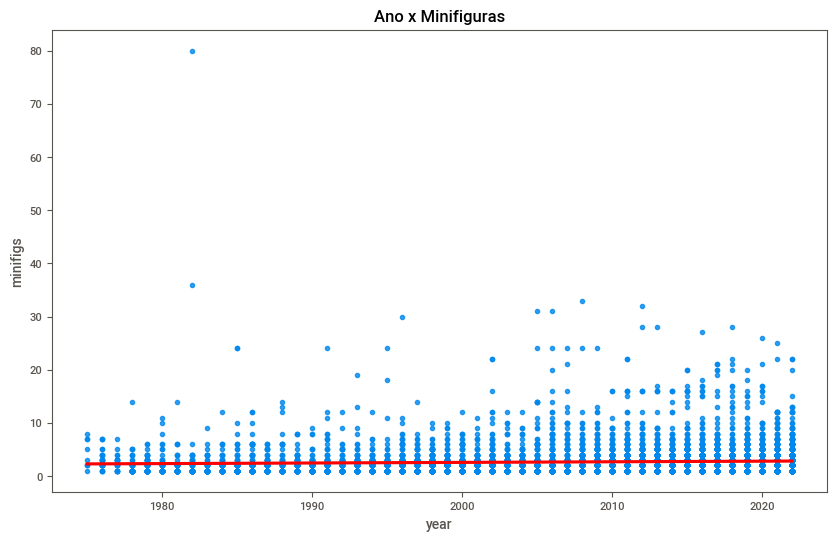

In [45]:
corr = df_model['pieces'].corr(df_model['minifigs'])

plt.figure(figsize=(10,6))

sns.regplot(
    data=df_model,
    x='year',
    y='minifigs',
    line_kws={'color':'red'}
)

plt.title(f'Ano x Minifiguras')

plt.show()

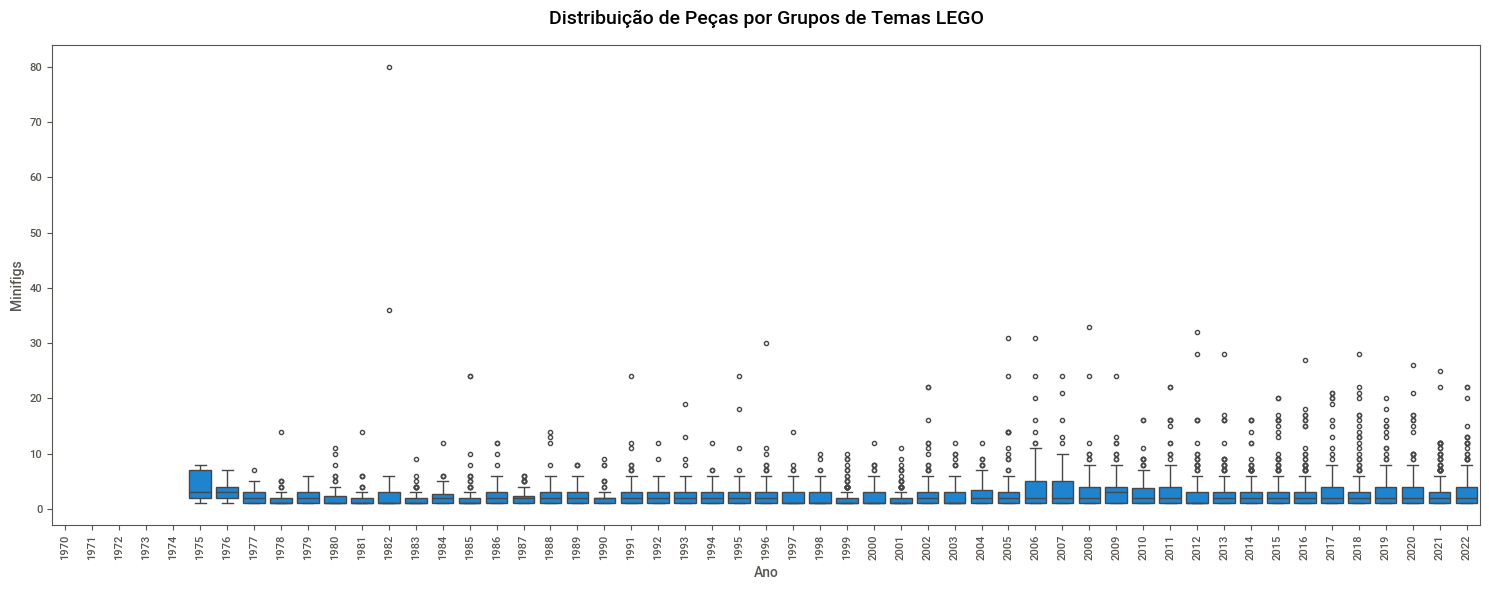

In [46]:
plt.figure(figsize=(15, 6))

sns.boxplot(
    data=df_model,
    x='year',
    y='minifigs'
)

plt.title(
    'Distribuição de Peças por Grupos de Temas LEGO',
    fontsize=14,
    pad=15
)

plt.xlabel('Ano')
plt.ylabel('Minifigs')

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

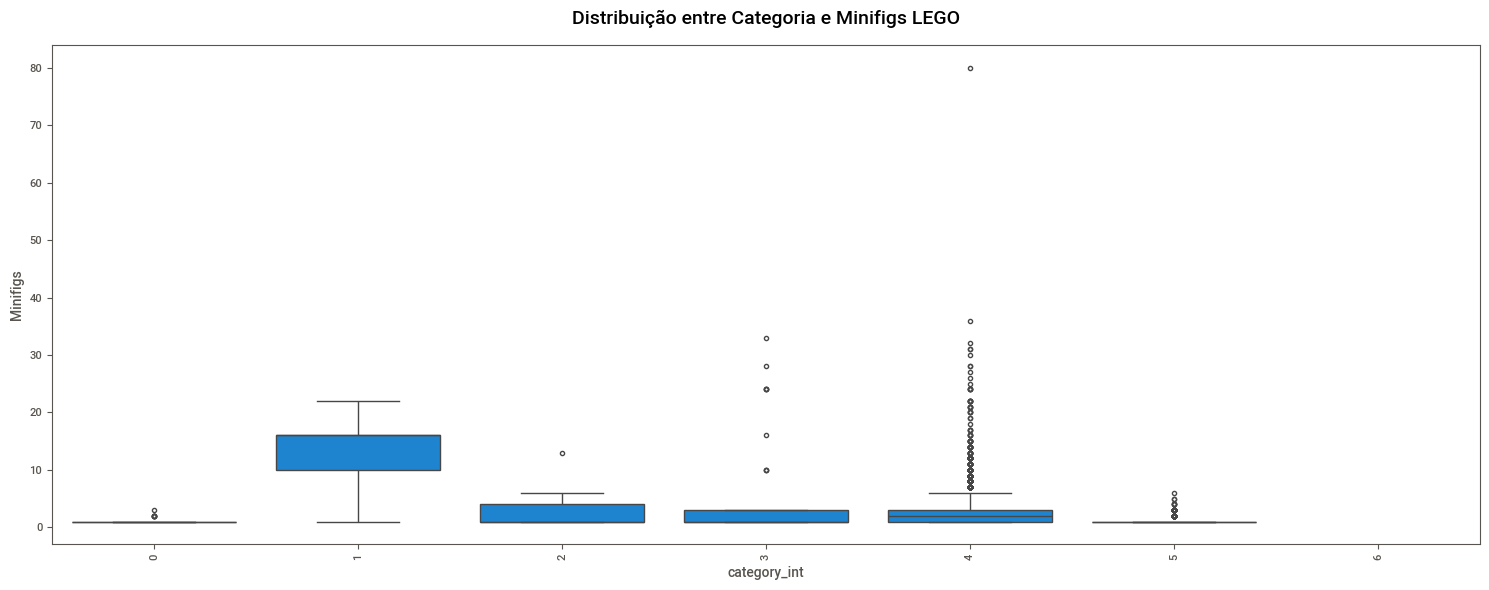

In [47]:
plt.figure(figsize=(15, 6))

sns.boxplot(
    data=df_model,
    x='category_int',
    y='minifigs'
)

plt.title(
    'Distribuição entre Categoria e Minifigs LEGO',
    fontsize=14,
    pad=15
)

plt.xlabel('category_int')
plt.ylabel('Minifigs')

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [48]:
df_model['minifigs'] = (
    df_model.groupby('category_int')['minifigs']
           .transform(lambda x: x.fillna(x.median()))
)

In [49]:
df_model['minifigs'] = (
    df_model.groupby('theme_group_int')['minifigs']
           .transform(lambda x: x.fillna(x.median()))
)

<Axes: >

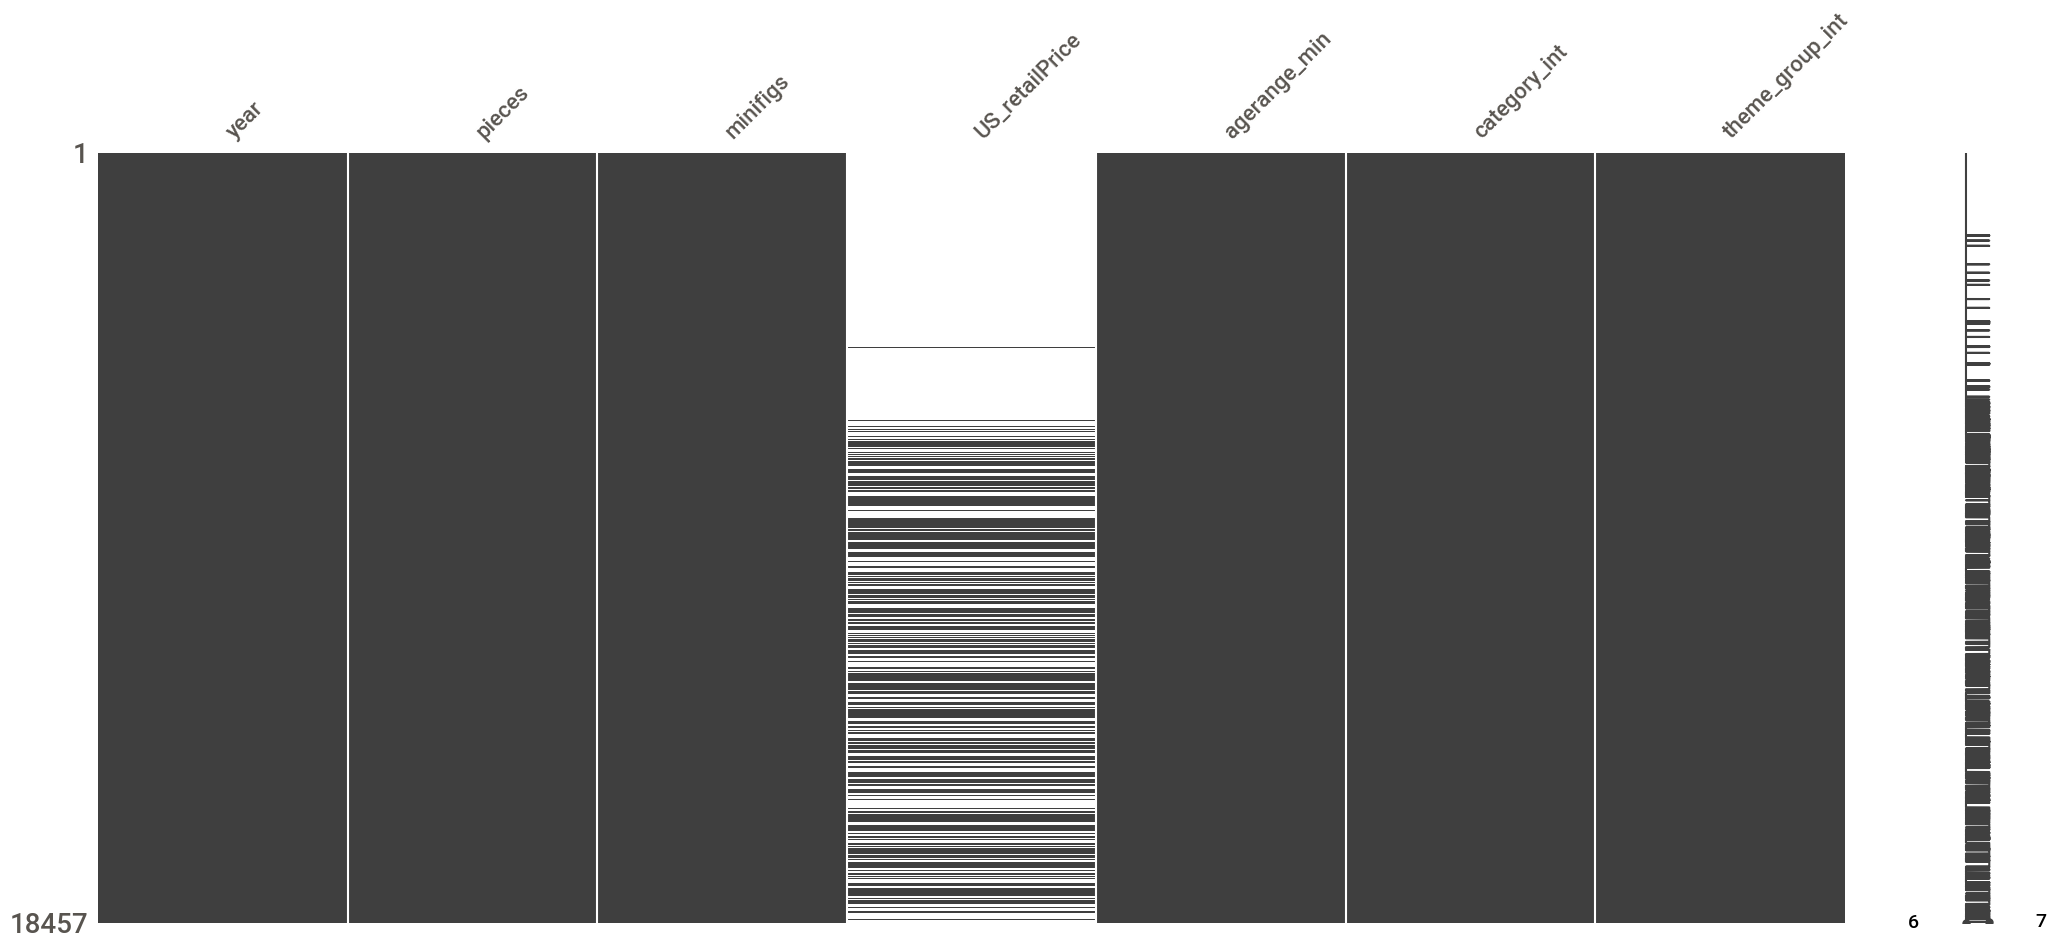

In [50]:
msno.matrix(df_model)

In [54]:
features = [
    'pieces',
    'minifigs',
    'agerange_min',
    'category_int',
    'theme_group_int',
    'year'
]

In [52]:
for col in features:
    print(col, df_model[col].isnull().sum())

NameError: name 'features' is not defined

In [53]:
lego_com_preco = df_model[df_model['US_retailPrice'].notna()].copy()

lego_sem_preco = df_model[df_model['US_retailPrice'].isna()].copy()

In [55]:
target = 'US_retailPrice'

In [56]:
X = lego_com_preco[features]
y = lego_com_preco[target]

In [57]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [58]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [59]:
from sklearn.neural_network import MLPRegressor

modelo = MLPRegressor(
    hidden_layer_sizes=(100, 50),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=42
)

In [60]:
modelo.fit(
    X_train_scaled,
    y_train
)

MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42)

In [61]:
y_pred = modelo.predict(X_test_scaled)

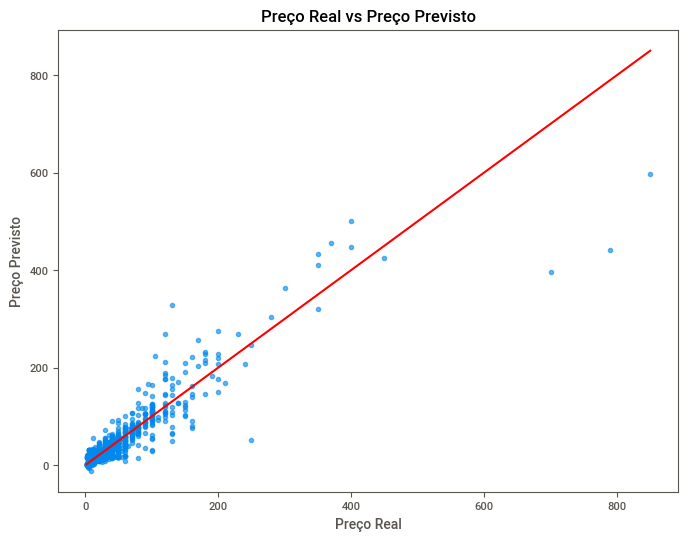

In [62]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel('Preço Real')
plt.ylabel('Preço Previsto')

plt.title('Preço Real vs Preço Previsto')

plt.show()

In [63]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print(f'R²: {r2:.4f}')

R²: 0.8323


In [64]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(
    y_test,
    y_pred
)

print(f'MAE: {mae:.2f}')

MAE: 11.00


In [65]:
from sklearn.metrics import root_mean_squared_error

rmse = root_mean_squared_error(
    y_test,
    y_pred
)

print(f'RMSE: {rmse:.2f}')

RMSE: 23.16


In [66]:
X_sem_preco = lego_sem_preco[features]

X_sem_preco_scaled = scaler.transform(
    X_sem_preco
)

precos_previstos = modelo.predict(
    X_sem_preco_scaled
)

lego_sem_preco['US_retailPrice'] = precos_previstos

In [67]:
lego_sem_preco.head()

,year,pieces,minifigs,US_retailPrice,agerange_min,category_int,theme_group_int
0,1970,67.0,2.0,10.074560,6.0,4,15
1,1970,109.0,2.0,12.213369,6.0,4,15
2,1970,158.0,2.0,14.731485,6.0,4,15
3,1970,233.0,2.0,18.695460,6.0,4,15
4,1970,49.0,2.0,9.157927,6.0,4,15


In [68]:
lego_df_final = pd.concat(
    [lego_com_preco, lego_sem_preco],
    ignore_index=True
)

lego_df_final = lego_df_final.rename(
    columns={'US_retailPrice': 'price'}
)

In [69]:
lego_df_final.head()

,year,pieces,minifigs,price,agerange_min,category_int,theme_group_int
0,1991,8.0,2.0,12.99,6.0,4,11
1,1991,8.0,2.0,12.99,6.0,4,11
2,1991,6.0,2.0,27.99,6.0,4,11
3,1991,3.0,2.0,41.99,6.0,4,11
4,1992,1.0,2.0,14.99,1.0,4,12


In [75]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))


MAE: 11.002360933818807
RMSE: 536.1761187095146
R²: 0.8322848479393661
